#### 2주차 보충학습_ 기술 통계 분석과 그래프

In [ ]:
# 데이터 출처: https://archive.ics.uci.edu/dataset/186/wine+quality
# ucimlrepo 라이브러리_Readme: https://github.com/uci-ml-repo/ucimlrepo
# %pip install ucimlrepo

# 데이터 불러오기
from ucimlrepo import fetch_ucirepo 

# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
  
# metadata 
print(wine_quality.metadata) 
  
# variable information 
print(wine_quality.variables) 

In [ ]:
# 라이브러리 기타 설정
# !c:\Users\jihun\anaconda3\Scripts\conda.exe install -n myenv -c conda-forge statsmodels -y

In [ ]:
print(type(wine_quality))          # 무슨 종류의 객체인지
print(wine_quality.keys())         # 맨 바깥 상자 안의 칸들
print(wine_quality.data.keys())    # data 칸 안의 칸들

In [10]:
df = wine_quality.data.original

print(df.shape)
print()

print(df.info())
print()

print(df.describe())
print()

df.head()

(6497, 13)

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 688.6 KB
None

       fixed_acidity  volatile_acidity  citric_acid  residua

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [11]:
print(df["color"].unique())

<ArrowStringArray>
['red', 'white']
Length: 2, dtype: str


In [ ]:
red_df = df[df["color"] == "red"].drop(columns="color").copy()
white_df = df[df["color"] == "white"].drop(columns="color").copy()

red_df.insert(0, "type", "red")
white_df.insert(0, "type", "white")

print(red_df.head())
print(white_df.head())

In [ ]:
print(red_df.shape)
print(white_df.shape)

In [ ]:
import pandas as pd
wine = pd.concat([red_df, white_df])
wine.shape

In [ ]:
import os

os.makedirs("./wine_regression", exist_ok=True)
wine.to_csv("./wine_regression/wine.csv", index=False)

In [ ]:
print(wine.info())

In [ ]:
display(wine.describe())

print(sorted(wine.quality.unique().tolist()))

display(wine.quality.value_counts())

In [ ]:
display(wine.groupby('type')['quality'].describe())

print(wine.groupby('type')['quality'].mean())
print(wine.groupby('type')['quality'].std())
print(wine.groupby('type')['quality'].agg(['mean', 'std']))


In [58]:
from scipy import stats
from statsmodels.formula.api import ols,glm

print(wine.columns)

red_wine_quality = wine.loc[wine['type'] == 'red', 'quality']
white_wine_quality = wine.loc[wine['type'] == 'white', 'quality']

print(stats.ttest_ind(red_wine_quality, white_wine_quality, equal_var=False))

Rformula = 'quality ~ fixed_acidity + volatile_acidity + citric_acid + residual_sugar + chlorides + free_sulfur_dioxide + total_sulfur_dioxide + density + pH + sulphates + alcohol'
regression_result = ols(Rformula, data = wine).fit()
regression_result.summary()

Index(['type', 'fixed_acidity', 'volatile_acidity', 'citric_acid',
       'residual_sugar', 'chlorides', 'free_sulfur_dioxide',
       'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='str')
TtestResult(statistic=np.float64(-10.149363059143164), pvalue=np.float64(8.168348870049669e-24), df=np.float64(2950.750452166697))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                quality   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     243.3
Date:                   금, 23 10 2026   Prob (F-statistic):               0.00
Time:                        16:05:20   Log-Likelihood:                -7215.5
No. Observations:                6497   AIC:                         1.445e+04
Df Residuals:                    6485   BIC:                         1.454e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               55.7627     11.894      4.688      0.000      32.447      79.079
fixed_acidity            0.0677      0.016      4.346      0.000       0.037       0.098
volatile_acidity        -1.3279      0.077    -17.162      0.000      -1.480      -1.176
citric_acid             -0.1097      0.080     -1.377      0.168      -0.266       0.046
residual_sugar           0.0436      0.005      8.449      0.000       0.033       0.054
chlorides               -0.4837      0.333     -1.454      0.146      -1.136       0.168
free_sulfur_dioxide      0.0060      0.001      7.948      0.000       0.004       0.007
total_sulfur_dioxide    -0.0025      0.000     -8.969      0.000      -0.003      -0.002
density                -54.9669     12.137     -4.529      0.000     -78.760     -31.173
pH                       0.4393      0.090      4.861      0.000       0.262       0.616
sulphates                0.7683      0.076     10.092      0.000       0.619       0.917
alcohol                  0.2670      0.017     15.963      0.000       0.234       0.300
==============================================================================
Omnibus:                      144.075   Durbin-Watson:                   1.646
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              324.712
Skew:                          -0.006   Prob(JB):                     3.09e-71
Kurtosis:                       4.095   Cond. No.                     2.49e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.49e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [61]:
sample1 = wine[wine.columns.difference(['quality', 'type'])]
sample1 = sample1[0:5][:]

sample1_predict = regression_result.predict(sample1)
display(sample1_predict)

print(wine[0:5]['quality'])

data = {"fixed_acidity" : [8.5, 8.1], "volatile_acidity" : [0.8, 0.5],
        "citric_acid" : [0.3, 0.4], "residual_sugar": [6.1, 5.8], "chlorides" : [0.055, 0.04],
        "free_sulfur_dioxide" : [30.0, 31.0], "total_sulfur_dioxide" : [98.0, 99], "density" : [0.996, 0.91],
        "pH" : [3.25, 3.01], "sulphates" : [0.4, 0.35], "alcohol" : [9.0, 0.88]}

sample2 = pd.DataFrame(data, columns=sample1.columns)
sample2

sample2_predict = regression_result.predict(sample2)
display(sample2_predict)

0    4.997607
1    4.924993
2    5.034663
3    5.680333
4    4.997607
dtype: float64

0    5
1    5
2    5
3    6
4    5
Name: quality, dtype: int64


0    4.809094
1    7.582129
dtype: float64

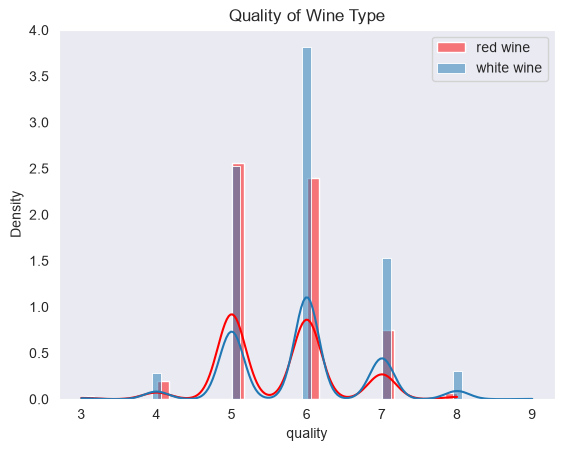

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('dark')
sns.histplot(red_wine_quality, stat = 'density', kde = True, color = "red",
             label = 'red wine')

sns.histplot(white_wine_quality, stat = 'density', kde = True,
             label = 'white wine')
plt.title("Quality of Wine Type")
plt.legend()
plt.show()

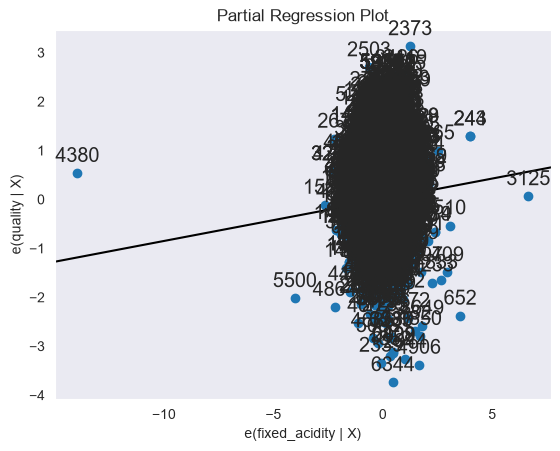

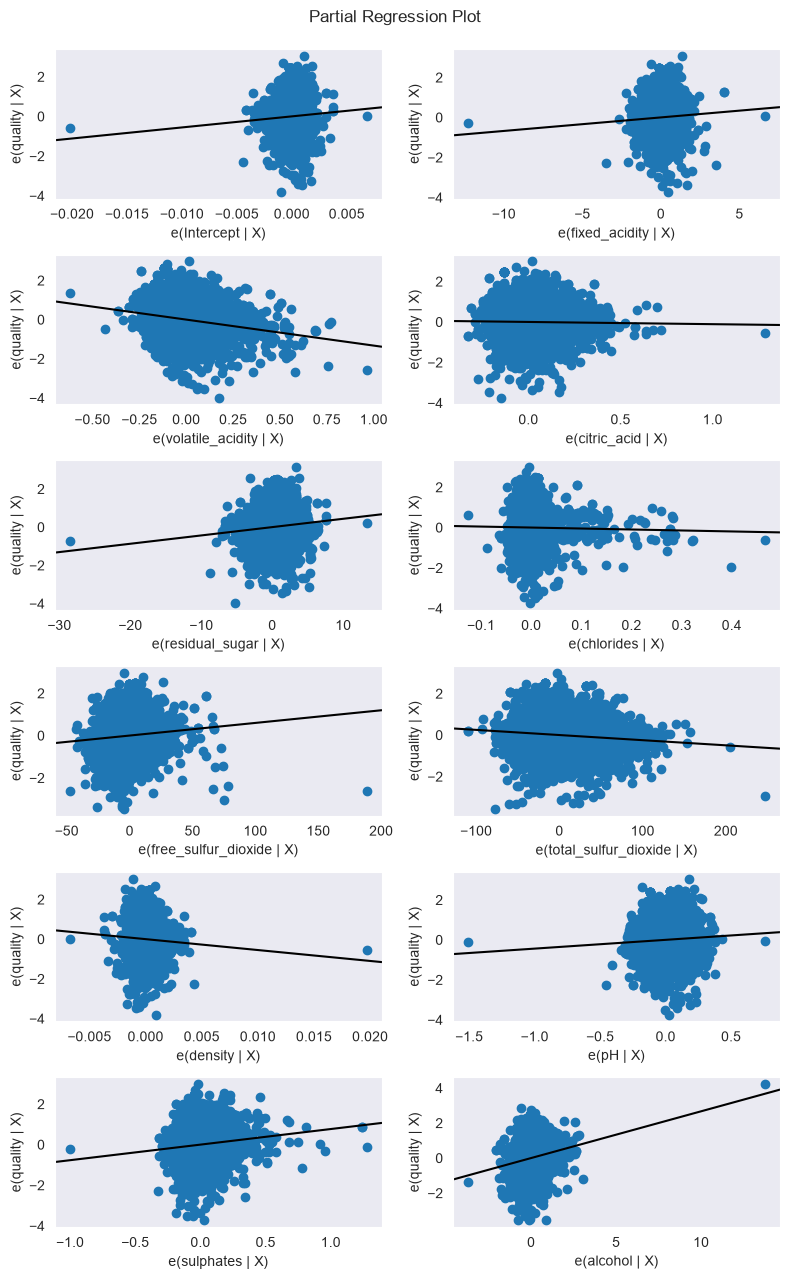

In [57]:
import statsmodels.api as sm
others = list(set(wine.columns).difference(set(["quality", "fixed_acidity"])))
p, resids = sm.graphics.plot_partregress("quality", "fixed_acidity", others, data = wine, ret_coords = True)
plt.show()
fig = plt.figure(figsize = (8, 13))
sm.graphics.plot_partregress_grid(regression_result, fig = fig)
plt.show()